# (DSC555) Data Extraction, Transformation, and Loading (ETL)
Author: Tracey Johnson/
Date: 10-07-2026/
Python version 3.13

This task involves the ETL steps needed to prepare the project’s data, pulling multiple years of Census and other public datasets, applying cleaning and structural fixes, and integrating them into a primary unified dataset and a secondary court-level dataset, both in an analysis‑ready format. It also includes data‑quality checks, such as validating ranges, checking missingness, and running brief EDA techniques like summary statistics and distribution scans, to ensure no critical issues are overlooked.


1. Data Collection
2. Data Cleaning and Preprocessing
3. Data Integration
4. Data Quality Checks and EDA
5. Save Processed Data

---

## Data Collection

All datasets for this project are collected from public sources and stored in the GitHub repository **access‑barriers‑analysis** to keep everything organized, versioned, and openly accessible. The repository holds raw downloads, cleaned outputs, and scripts in a structured layout so the full data pipeline can be reproduced or reviewed at any time. Using GitHub ensures transparent updates, stable storage, and clear tracking of changes as the analysis evolves.

Import libraries.

In [61]:
import pandas as pd
import requests
import io
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully.")

Libraries imported successfully.


### Census American Community Survey (ACS)

The ACS provides annual tract‑level demographic and socioeconomic data used to describe community conditions, offering standardized measures across topics such as population characteristics, housing, economic indicators, commuting, and digital access. These tables form the foundation for understanding local context and allow consistent comparison across geographies and years.

**Raw status:**  
ACS tables are provided as wide CSV files with separate estimate and margin‑of‑error columns. Table structures and variable names can vary across years, and the DP and S tables contain nested column formats that require standardization before use.

**Collection process:**  
Raw ACS CSVs are downloaded from the Census Bureau and stored in the project’s GitHub Release for versioned access. During preprocessing, each annual dataset is cleaned, reshaped, and harmonized, then written out as local Parquet files to support faster reads and consistent schema handling. The final integrated ACS dataset will also be saved as a single Parquet file, which is expected to be compact enough to store directly in the repository branch.

**Unique tools or methods:**  
Although ACS data can be accessed through the Census Data API, this project uses direct CSV downloads to ensure reproducibility across years. Processing includes reshaping wide tables, selecting relevant variables, standardizing column names, and aligning GEOIDs for tract‑level integration with other datasets.

**Types of ACS Tables Downloaded**
- DP02 – Selected Social Characteristics  
- DP03 – Selected Economic Characteristics  
- DP04 – Selected Housing Characteristics  
- DP05 – Demographic and Housing Estimates  
- S2801 – Types of Computers and Internet Subscriptions  

In [2]:
urls = {
    2019: "https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2019_DP02_Data.parquet",
    2020: "https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2020_DP02_Data.parquet",
    2021: "https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2021_DP02_Data.parquet",
    2022: "https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2022_DP02_Data.parquet",
    2023: "https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2023_DP02_Data.parquet",
    2024: "https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2024_DP02_Data.parquet"
}

dfs = []

In [3]:
for year, url in urls.items():
    print(f"\nFetching: {url}")
    response = requests.get(url)
    print(response.content[:20])

    df = pd.read_parquet(io.BytesIO(response.content))
    df["year"] = year
    dfs.append(df)

# Merged dataset
df_acs = pd.concat(dfs, ignore_index=True)


Fetching: https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2019_DP02_Data.parquet
b'PAR1\x15\x04\x15\xea\xff\x80\x01\x15\x9c\x80\x1bL\x15\x80\xb0\x05'

Fetching: https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2020_DP02_Data.parquet
b'PAR1\x15\x04\x15\xea\xff\x80\x01\x15\xd6\xfa\x1aL\x15\x80\xb0\x05'

Fetching: https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2021_DP02_Data.parquet
b'PAR1\x15\x04\x15\xea\xff\x80\x01\x15\xd6\xfa\x1aL\x15\x80\xb0\x05'

Fetching: https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2022_DP02_Data.parquet
b'PAR1\x15\x04\x15\xea\xff\x80\x01\x15\xca\xf9\x1aL\x15\x80\xb0\x05'

Fetching: https://github.com/tdjohnson3210-oss/access-barriers-analysis/releases/download/v1.0/ACSDP5Y2023_DP02_Data.parquet
b'PAR1\x15\x04\x15\xea\xff\x80\x01\x15\xca\xf9\x1aL\x15\x80\xb0\x05'

Fetching: https://github

### Rural–Urban Commuting Area (RUCA) Codes – USDA

RUCA codes classify census tracts based on rurality and commuting patterns. They provide geographic context that helps differentiate urban, suburban, micropolitan, small‑town, and rural areas.

**Raw status:**  
RUCA data is provided as a structured CSV containing tract‑level codes. The dataset is tidy, with one row per tract, and includes primary RUCA codes, secondary codes, and collapsed categories. The 2020 RUCA release—updated to align with 2020 Census tract boundaries—will be used for this project. These tract boundaries remain stable across ACS releases from 2019 through 2024, and RUCA classifications are not updated annually, making the 2020 version appropriate for multi‑year analysis.

**Collection process:**  
Data is downloaded directly from the USDA Economic Research Service website as a CSV file. The 2020 version is a single nationwide file.

**Unique tools or methods:**  
No specialized tools are required beyond standard CSV loading. Integration involves merging RUCA codes with ACS tract‑level data and aggregating to county level when aligning with court datasets.



In [4]:
url = "https://raw.githubusercontent.com/tdjohnson3210-oss/access-barriers-analysis/main"

In [5]:
df_ruca = pd.read_csv(
    f"{url}/data_raw/RUCA-codes-2020-tract.csv",
    encoding="latin1"
)


### National Center for State Court (NCSC) - Court Statistics Project

The Court Statistics Project provides annual state‑level civil caseload data that summarizes basic case characteristics such as filing volumes, case types, and dispositions. This dataset offers a high‑level view of civil court activity and supports comparisons across states and over time.

**Raw status:**  
The CSP civil dataset is provided as a structured CSV containing aggregated state‑level counts. It includes basic descriptive fields (e.g., case category, filings, dispositions) and contains no personally identifiable information (PII). The dataset is tidy, with one row per state‑year.

**Collection process:**  
The civil dataset used in this project was requested directly from NCSC, but the same information is also publicly accessible through the Court Statistics Project online data dashboard, where tables can be downloaded in CSV format. Because the dataset is state‑level, no tract or county identifiers are present.

In [6]:
df_csp = pd.read_csv(
    f"{url}/data_raw/NCSC-CSP-filtered.csv",
    encoding="latin1"
)

C:\Users\tdjoh\AppData\Local\Temp\ipykernel_37224\2939019394.py:1: DtypeWarning: Columns (0,1,3,4,5,10,15,19,21,23,25,27,29,32) have mixed types. Specify dtype option on import or set low_memory=False.
  df_csp = pd.read_csv(


---

## Data Cleaning and Preprocessing

This section will focus on basic data cleaning steps such as handling missing values, correcting data types, and standardization of the datasets. Each dataset will be processed individually, while Census data tables will be integrated early in the preprocessing workflow to ensure consistency and completeness across all datasets.

### RUCA

In [7]:
print("Shape of the dataset:")
print(df_ruca.shape)

Shape of the dataset:
(85528, 27)


A historical snapshot of the dataset is provided below, showing the first and last five rows.

In [8]:
print("First 5 rows of the dataset:")
print(df_ruca.head())
print("Last 5 rows of the dataset:")
print(df_ruca.tail())

First 5 rows of the dataset:
    TractFIPS23  CountyFIPS23  CountyCode23    CountyName23  TractFIPS20  \
0  1.001020e+09        1001.0           1.0  Autauga County   1001020100   
1  1.001020e+09        1001.0           1.0  Autauga County   1001020200   
2  1.001020e+09        1001.0           1.0  Autauga County   1001020300   
3  1.001020e+09        1001.0           1.0  Autauga County   1001020400   
4  1.001021e+09        1001.0           1.0  Autauga County   1001020501   

   TractCode20          TractName20  CountyFIPS20  CountyCode20  \
0        20100     Census Tract 201          1001             1   
1        20200     Census Tract 202          1001             1   
2        20300     Census Tract 203          1001             1   
3        20400     Census Tract 204          1001             1   
4        20501  Census Tract 205.01          1001             1   

     CountyName20  ...  PrimaryRUCADescription PrimaryDestinationCode  \
0  Autauga County  ...       Metropoli

Check for duplicate rows in the dataset.

In [9]:
print("Number of duplicate rows:", df_ruca.duplicated().sum())

Number of duplicate rows: 0


Check for missing values in the dataset.

In [10]:
print("Missing values in each column (%):", df_ruca.isnull().sum() / len(df_ruca) * 100)

Missing values in each column (%): TractFIPS23                  0.004677
CountyFIPS23                 0.004677
CountyCode23                 0.004677
CountyName23                 0.004677
TractFIPS20                  0.000000
TractCode20                  0.000000
TractName20                  0.000000
CountyFIPS20                 0.000000
CountyCode20                 0.000000
CountyName20                 0.000000
StateFIPS20                  0.000000
StateName20                  0.000000
UrbanAreaCode20             21.888738
UrbanAreaName20             21.888738
UrbanCore                    0.000000
UrbanCoreType                0.000000
PrimaryRUCA                  0.000000
PrimaryRUCADescription       0.000000
PrimaryDestinationCode       1.874240
PrimaryDestinationName       1.874240
SecondaryRUCA                0.000000
SecondaryRUCADescription     0.000000
SecondaryDestinationCode     1.931531
SecondaryDestinationName     1.931531
Population                   0.000000
LandArea       

Drop columns that had high missing percentages or were not relevant for merging with ACS tract‑level data. The remaining fields include the core RUCA identifiers and rurality classifications needed for analysis, while the removed columns were mostly optional metadata that don’t affect the results.

In [11]:
cols_to_drop_ruca = [
    "UrbanAreaCode20",
    "UrbanAreaName20",
    "PrimaryDestinationCode",
    "PrimaryDestinationName",
    "SecondaryDestinationCode",
    "SecondaryDestinationName",
    "TractFIPS23",
    "CountyFIPS23",
    "CountyCode23",
    "CountyName23"
]

In [12]:
df_ruca_processed = df_ruca.copy()
df_ruca_processed.drop(columns=cols_to_drop_ruca, inplace=True)

Convert tract datatypes to string for consistency with ACS tract‑level data.

In [13]:
df_ruca_processed = df_ruca_processed.assign(
    TractFIPS20=df_ruca_processed.TractFIPS20.astype(str),
    CountyFIPS20=df_ruca_processed.CountyFIPS20.astype(str),
    StateFIPS20=df_ruca_processed.StateFIPS20.astype(str),
    SecondaryRUCA=df_ruca_processed.SecondaryRUCA.round().astype("Int64")
)

In [14]:
print(df_ruca_processed.dtypes)

TractFIPS20                  object
TractCode20                   int64
TractName20                  object
CountyFIPS20                 object
CountyCode20                  int64
CountyName20                 object
StateFIPS20                  object
StateName20                  object
UrbanCore                     int64
UrbanCoreType                object
PrimaryRUCA                   int64
PrimaryRUCADescription       object
SecondaryRUCA                 Int64
SecondaryRUCADescription     object
Population                    int64
LandArea                    float64
PopDensity                  float64
dtype: object


Snake-case column names for consistency and remove white spaces.

In [15]:
df_ruca_processed.columns = (
    df_ruca_processed.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("-", "_")
        .str.replace(r"[^0-9a-zA-Z_]", "", regex=True)
)

Remove leading/trailing whitespace from values from text columns.

In [16]:
for col in df_ruca_processed.select_dtypes(include="object").columns:
    df_ruca_processed[col] = df_ruca_processed[col].str.strip()

### Court Statistics Project (NCSC)

In [17]:
print("Shape of the dataset:")
print(df_csp.shape)

Shape of the dataset:
(140910, 33)


A historical snapshot of the dataset is provided below, showing the first and last five rows.

In [18]:
print("First 5 rows of the dataset:")
print(df_csp.head())
print("Last 5 rows of the dataset:")
print(df_csp.tail())

First 5 rows of the dataset:
                                     Id ReportingUnitIdentification  \
0  095CD8EC-E08F-41DC-B0C7-01D1989CBE9F                       IN-GJ   
1  F3721030-90AC-44EA-95DB-0302B759F981                       MN-GJ   
2  2DE154B9-E4C8-49B0-91B7-05AC3DDF5723                       MO-GJ   
3  BD4ADFD6-791D-4D25-8692-06C971D044BC                       GA-LJ   
4  C3CB11C7-9533-4817-ADC9-08B76143DE94                       IN-GJ   

   ReportingDate ReportingState ReportingJurisdiction       CaseCategory  \
0         2023.0             IN                    GJ  CivilCaseCategory   
1         2020.0             MN                    GJ  CivilCaseCategory   
2         2015.0             MO                    GJ  CivilCaseCategory   
3         2021.0             GA                    LJ  CivilCaseCategory   
4         2017.0             IN                    GJ  CivilCaseCategory   

   NewFiling  Reopened  Reactivated  TotalIncoming  ...  \
0   328484.0       0.0      

Some columns require value standardization to ensure consistency across datasets.

In [19]:
# Clean and standardize CSP id fields
df_csp["ReportingUnitIdentification"] = (
    df_csp["ReportingUnitIdentification"].str.split("-").str[1].str.upper()
)

df_csp["ReportingState"] = df_csp["ReportingState"].str.upper()
df_csp["ReportingJurisdiction"] = df_csp["ReportingJurisdiction"].str.upper()

Check for duplicate rows in the dataset. Data loaded with additional blank rows that need to be removed.

In [20]:
df_csp = df_csp.dropna(how="all")
print("Number of duplicate rows after blank rows removed:", df_csp.duplicated().sum())
print("Shape of the dataset after removing blank rows:", df_csp.shape)

Number of duplicate rows after blank rows removed: 0
Shape of the dataset after removing blank rows: (56, 33)


Check for missing values in the dataset.

In [21]:
print("Missing values in each column (%):", df_csp.isnull().sum() / len(df_csp) * 100)

Missing values in each column (%): Id                                              0.000000
ReportingUnitIdentification                     0.000000
ReportingDate                                   0.000000
ReportingState                                  0.000000
ReportingJurisdiction                           0.000000
CaseCategory                                    0.000000
NewFiling                                       0.000000
Reopened                                        0.000000
Reactivated                                     0.000000
TotalIncoming                                   0.000000
IncomingCasesPublishCode                        0.000000
EntryOfJudgement                                0.000000
ReopenedDisposition                             0.000000
PlacedOnInactiveStatus                          0.000000
TotalOutgoing                                   0.000000
OutgoingCasesPublishCode                        0.000000
EndPendingActive                                0.000

Columns containing publishing flags and fields with high missingness were removed because they do not provide analytical value for caseload modeling or integration with ACS data.

In [22]:
cols_to_drop_csp = [
    "IncomingCasesPublishCode",
    "OutgoingCasesPublishCode",
    "EndPendingPublishCode",
    "SetForReviewPublishCode",
    "CaseWithSelfRepresentedLitigantsPublishCode",
    "CaseWithInterpretersPublishCode",
    "JuryTrialPublishCode",
    "BenchNonJuryTrialPublishCode",
    "TotalDispositionsPublishCode",
    "SetForReviewQuantity"
]

In [23]:
df_csp_processed = df_csp.copy()
df_csp_processed.drop(columns=cols_to_drop_csp, inplace=True)

Check data types.

In [24]:
df_csp_processed = df_csp_processed.assign(
    Id=df_csp_processed.Id.astype(str),
    ReportingUnitIdentification=df_csp_processed.ReportingUnitIdentification.astype(str),
    ReportingDate=df_csp_processed.ReportingDate.astype("Int64")
)

In [25]:
print(df_csp_processed.dtypes)

Id                                   object
ReportingUnitIdentification          object
ReportingDate                         Int64
ReportingState                       object
ReportingJurisdiction                object
CaseCategory                         object
NewFiling                           float64
Reopened                            float64
Reactivated                         float64
TotalIncoming                       float64
EntryOfJudgement                    float64
ReopenedDisposition                 float64
PlacedOnInactiveStatus              float64
TotalOutgoing                       float64
EndPendingActive                    float64
EndPendingInactive                  float64
TotalEndPending                     float64
CaseWithSelfRepresentedLitigants    float64
CaseWithInterpreters                float64
JuryTrial                           float64
BenchNonJuryTrial                   float64
NonTrialDisposition                 float64
TotalDispositions               

Snake-case column names for consistency.

In [26]:
df_csp_processed.columns = (
    df_csp_processed.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("-", "_")
        .str.replace(r"[^0-9a-zA-Z_]", "", regex=True)
)

Remove leading/trailing whitespace from values from text columns.

In [27]:
for col in df_csp_processed.select_dtypes(include="object").columns:
    df_csp_processed[col] = df_csp_processed[col].str.strip()

### Census ACS

After merge, realized that tables had 2 header rows, which needed to be addressed before further processing.

In [28]:
# Use the first row as column names
df_acs.columns = df_acs.iloc[0]
df_acs = df_acs.iloc[1:].reset_index(drop=True)

There are > 600 columns and it is necessary to carefully select the relevant ones for analysis and remove the blank or unnecessary columns.

In [29]:
df_acs = df_acs[[c for c in df_acs.columns 
                 if "Margin of Error" not in str(c) 
                 and "Percent Margin" not in str(c)]]

irrelevant_topics = [
    "FERTILITY",
    "GRANDPARENTS",
    "SCHOOL ENROLLMENT",
    "VETERAN STATUS",
    "MARITAL STATUS",
    "RELATIONSHIP",
    "PLACE OF BIRTH",
    "WORLD REGION",
    "YEAR OF ENTRY",
    "U.S. CITIZENSHIP STATUS"
]

df_acs = df_acs[[c for c in df_acs.columns 
                 if not any(topic in str(c) for topic in irrelevant_topics)]]

garbage_cols = ["None", "nan", "NaN", 2019, 2020, 2021, 2022, 2023, 2024]

df_acs = df_acs.drop(columns=[c for c in df_acs.columns 
                              if str(c) in garbage_cols], errors="ignore")

df_acs = df_acs[[c for c in df_acs.columns
                 if not str(c).endswith("!!Total")
                 and not str(c).endswith("Total households")
                 and not str(c).endswith("Total population")
                 and not str(c).endswith("Total Civilian Noninstitutionalized Population")]]

In [30]:
def clean_colname(col):
    col = str(col)

    # Remove leading prefixes like Estimate!!, Percent!!, etc.
    col = col.replace("Estimate!!", "")
    col = col.replace("Percent!!", "")
    col = col.replace("Margin of Error!!", "")
    col = col.replace("Percent Margin of Error!!", "")

    # Split on !! and keep meaningful parts
    parts = [p.strip() for p in col.split("!!") if p.strip()]

    # Convert to snake_case
    col = "_".join(parts)
    col = col.lower()

    # Remove special characters
    col = col.replace(",", "")
    col = col.replace("(", "")
    col = col.replace(")", "")
    col = col.replace("-", "_")
    col = col.replace(" ", "_")

    # Remove double underscores
    while "__" in col:
        col = col.replace("__", "_")

    return col

# Apply to all columns
df_acs.columns = [clean_colname(c) for c in df_acs.columns]

In [31]:
print("Shape of the dataset:")
print(df_acs.shape)

Shape of the dataset:
(500955, 167)


A historical snapshot of the dataset is provided below, showing the first and last five rows.

In [32]:
print("First 5 rows of the dataset:")
print(df_acs.head())
print("Last 5 rows of the dataset:")
print(df_acs.tail())

First 5 rows of the dataset:
              geography                       geographic_area_name  \
0  1400000US01001020100  Census Tract 201, Autauga County, Alabama   
1  1400000US01001020200  Census Tract 202, Autauga County, Alabama   
2  1400000US01001020300  Census Tract 203, Autauga County, Alabama   
3  1400000US01001020400  Census Tract 204, Autauga County, Alabama   
4  1400000US01001020500  Census Tract 205, Autauga County, Alabama   

  households_by_type_total_households_married_couple_family  \
0                                                409          
1                                                235          
2                                                628          
3                                                944          
4                                               2231          

  households_by_type_total_households_married_couple_family_with_own_children_of_the_householder_under_18_years  \
0                                                145    

Check for duplicate rows in the dataset. ACS can have duplicate rows across years and geographic regions.

In [33]:
print("Number of duplicate rows:", df_acs.duplicated().sum())

Number of duplicate rows: 0


In [34]:
df_acs = df_acs.drop_duplicates()
print("Number of duplicate rows after removal:", df_acs.duplicated().sum())

Number of duplicate rows after removal: 0


Check for missing values in the dataset. 1.16% missing across some columns, acceptable for further analysis.

In [35]:
print("Missing values in each column (%):", df_acs.isnull().sum() / len(df_acs) * 100)

Missing values in each column (%): geography                                                                                                        0.00000
geographic_area_name                                                                                             0.00000
households_by_type_total_households_married_couple_family                                                        1.16777
households_by_type_total_households_married_couple_family_with_own_children_of_the_householder_under_18_years    1.16777
households_by_type_total_households_cohabiting_couple_household                                                  1.16777
                                                                                                                  ...   
ancestry_total_population_welsh                                                                                  1.16777
ancestry_total_population_west_indian_excluding_hispanic_origin_groups                                           1.167

This step cleans the geography field by splitting out tract, county, and state, renames the original column, and converts each new field to a string.

In [36]:
# Split geography
df_acs["state"] = df_acs["geographic_area_name"].str.rsplit(",", n=1).str[1].str.strip()
df_acs["county"] = df_acs["geographic_area_name"].str.rsplit(",", n=2).str[1].str.strip()
df_acs["tract_name"] = df_acs["geographic_area_name"].str.rsplit(",", n=2).str[0].str.strip()

# Extract 11-digit GEOID from ACS 'geography' column
df_acs["geoid"] = df_acs["geography"].astype(str).str[-11:]

# Rename columns
df_acs = df_acs.rename(columns={"geographic_area_name": "full_geography_name"})

# Convert columns to string
df_acs["tract_name"] = df_acs["tract_name"].astype(str)
df_acs["county"] = df_acs["county"].astype(str)
df_acs["state"] = df_acs["state"].astype(str)
df_acs["full_geography_name"] = df_acs["full_geography_name"].astype(str)
df_acs["geoid"] = df_acs["geoid"].astype(str)

Check data types. Good for moving forward with geographic analysis and modeling.

In [37]:
df_acs = df_acs.loc[:, ~df_acs.columns.duplicated()]
non_numeric = ['geography', 'full_geography_name', 'state', 'county', 'tract_name', 'geoid', '2019']
numeric_cols = [col for col in df_acs.columns if col not in non_numeric]

In [38]:
for col in numeric_cols:
    df_acs[col] = pd.to_numeric(df_acs[col], errors='coerce')

In [39]:
df_acs.dtypes

geography                                                                                                         object
full_geography_name                                                                                               object
households_by_type_total_households_married_couple_family                                                        float64
households_by_type_total_households_married_couple_family_with_own_children_of_the_householder_under_18_years    float64
households_by_type_total_households_cohabiting_couple_household                                                  float64
                                                                                                                  ...   
2019                                                                                                               int64
state                                                                                                             object
county                          

Remove leading/trailing whitespace from values from text columns.

In [40]:
df_acs_processed = df_acs.copy()

In [41]:
for col in df_acs_processed.columns:
    if pd.api.types.is_string_dtype(df_acs_processed[col]):
        df_acs_processed[col] = df_acs_processed[col].str.strip()

### Findings from Data Cleaning and Preprocessing

The cleaning and preprocessing workflow standardizes all raw inputs, fixes structural inconsistencies, and prepares each dataset for integration. ACS tables are reshaped and converted to efficient Parquet files, while RUCA codes are trimmed to essential tract‑level identifiers and rurality classifications. After both datasets are cleaned, they are merged using tract identifiers to produce a unified, analysis‑ready file that supports consistent geographic comparison and downstream modeling.

---

## Data Integration

At this stage, there will be two main datasets: 
- The first contains geographical information and census data.
- The second dataset will serve as a secondary source of information, containing civil filing data.

### Check validity of geographical tracts

In [42]:
# ACS: Duplicates are ok due to multiple years
acs_geoids = df_acs_processed["geoid"].astype(str)
acs_invalid_length = acs_geoids.str.len() != 11
acs_non_numeric = ~acs_geoids.str.isnumeric()
acs_dupes = acs_geoids.duplicated(keep=False)

print("ACS invalid length:", acs_invalid_length.sum())
print("ACS non-numeric:", acs_non_numeric.sum())
print("ACS duplicates:", acs_dupes.sum())

ACS invalid length: 5
ACS non-numeric: 5
ACS duplicates: 489476


In [43]:
# Drop invalid ids
df_acs_processed = df_acs_processed[
    df_acs_processed["geoid"].astype(str).str.len() == 11
]

df_acs_processed = df_acs_processed[
    df_acs_processed["geoid"].astype(str).str.isnumeric()
]

In [44]:
# RUCA
ruca_geoids = df_ruca_processed["tractfips20"].astype(str).str.zfill(11)
ruca_invalid_length = ruca_geoids.str.len() != 11
ruca_non_numeric = ~ruca_geoids.str.isnumeric()
ruca_dupes = ruca_geoids.duplicated(keep=False)

print("RUCA invalid length:", ruca_invalid_length.sum())
print("RUCA non-numeric:", ruca_non_numeric.sum())
print("RUCA duplicates:", ruca_dupes.sum())

RUCA invalid length: 0
RUCA non-numeric: 0
RUCA duplicates: 0


In [45]:
ruca_geoids = df_ruca_processed["tractfips20"].astype(str).str.zfill(11)

acs_in_ruca = df_acs_processed["geoid"].isin(ruca_geoids)
print("ACS tracts found in RUCA:", acs_in_ruca.sum())
print("ACS tracts NOT found in RUCA:", (~acs_in_ruca).sum())

ruca_in_acs = ruca_geoids.isin(df_acs_processed["geoid"])
print("RUCA tracts found in ACS:", ruca_in_acs.sum())
print("RUCA tracts NOT found in ACS:", (~ruca_in_acs).sum())


ACS tracts found in RUCA: 486819
ACS tracts NOT found in RUCA: 14131
RUCA tracts found in ACS: 85395
RUCA tracts NOT found in ACS: 133


In [46]:
print(df_ruca_processed.columns)

Index(['tractfips20', 'tractcode20', 'tractname20', 'countyfips20',
       'countycode20', 'countyname20', 'statefips20', 'statename20',
       'urbancore', 'urbancoretype', 'primaryruca', 'primaryrucadescription',
       'secondaryruca', 'secondaryrucadescription', 'population', 'landarea',
       'popdensity'],
      dtype='object')


Merge relevant RUCA columns into the ACS dataframe based on geographic IDs.

In [47]:
df_ruca_processed["geoid"] = df_ruca_processed["tractfips20"].astype(str).str.zfill(11)

# select columns
ruca_cols = [
    "geoid",
    "statefips20", "statename20",
    "countyfips20", "countycode20", "countyname20",
    "urbancore", "urbancoretype",
    "primaryruca", "primaryrucadescription",
    "secondaryruca", "secondaryrucadescription",
    "population", "landarea", "popdensity"
]

df_ruca_subset = df_ruca_processed[ruca_cols]
df_merged = df_acs_processed.merge(
    df_ruca_subset,
    on="geoid",
    how="left"
)

In [48]:
df_merged.rename(columns={'2019': 'year'}, inplace=True)

---

## Data Quality Checks and EDA

Assess the quality of the cleaned and preprocessed datasets.

### Primary Dataset

Will only focus on a single year for EDA in larger dataset.

In [52]:
df_acs_2019 = df_acs[df_acs['2019'] == 2019].copy()
print("Rows in 2019 subset:", df_acs_2019.shape[0])
df_acs_2019.head()

Rows in 2019 subset: 74001


,geography,full_geography_name,households_by_type_total_households_married_couple_family,households_by_type_total_households_married_couple_family_with_own_children_of_the_householder_under_18_years,households_by_type_total_households_cohabiting_couple_household,households_by_type_total_households_cohabiting_couple_household_with_own_children_of_the_householder_under_18_years,households_by_type_total_households_male_householder_no_spouse/partner_present,households_by_type_total_households_male_householder_no_spouse/partner_present_with_own_children_of_the_householder_under_18_years,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,...,ancestry_total_population_ukrainian,ancestry_total_population_welsh,ancestry_total_population_west_indian_excluding_hispanic_origin_groups,computers_and_internet_use_total_households_with_a_computer,computers_and_internet_use_total_households_with_a_broadband_internet_subscription,2019,state,county,tract_name,geoid
0,1400000US01001020100,"Census Tract 201, Autauga County, Alabama",409.0,145.0,21.0,5.0,73.0,21.0,45.0,23.0,...,0.0,0.0,0.0,578.0,525.0,2019,Alabama,Autauga County,Census Tract 201,01001020100
1,1400000US01001020200,"Census Tract 202, Autauga County, Alabama",235.0,107.0,40.0,3.0,181.0,0.0,116.0,14.0,...,0.0,27.0,0.0,514.0,460.0,2019,Alabama,Autauga County,Census Tract 202,01001020200
2,1400000US01001020300,"Census Tract 203, Autauga County, Alabama",628.0,301.0,135.0,0.0,223.0,33.0,176.0,34.0,...,0.0,7.0,0.0,1196.0,1093.0,2019,Alabama,Autauga County,Census Tract 203,01001020300
3,1400000US01001020400,"Census Tract 204, Autauga County, Alabama",944.0,230.0,39.0,21.0,295.0,43.0,185.0,49.0,...,0.0,33.0,11.0,1551.0,1434.0,2019,Alabama,Autauga County,Census Tract 204,01001020400
4,1400000US01001020500,"Census Tract 205, Autauga County, Alabama",2231.0,1140.0,25.0,0.0,842.0,37.0,661.0,185.0,...,0.0,180.0,0.0,4246.0,3991.0,2019,Alabama,Autauga County,Census Tract 205,01001020500


In [59]:
import pandas as pd

print("Shape:", df_acs_2019.shape)

print("\nColumn Types (first 30):")
display(df_acs_2019.dtypes.head(30))

print("\nMissing Values (Top 20):")
missing = df_acs_2019.isna().sum().sort_values(ascending=False)
display(missing.head(20))

print("\nDescriptive Statistics (numeric only):")
desc = df_acs_2019.describe().T
display(desc.head(20))

Shape: (74001, 89)

Column Types (first 30):


geography                                                                                                                                object
full_geography_name                                                                                                                      object
households_by_type_total_households_married_couple_family                                                                               float64
households_by_type_total_households_married_couple_family_with_own_children_of_the_householder_under_18_years                           float64
households_by_type_total_households_cohabiting_couple_household                                                                         float64
households_by_type_total_households_cohabiting_couple_household_with_own_children_of_the_householder_under_18_years                     float64
households_by_type_total_households_male_householder_no_spouse/partner_present                                                          


Missing Values (Top 20):


households_by_type_total_households_average_family_size                                                                         1825
households_by_type_total_households_average_household_size                                                                      1802
language_spoken_at_home_population_5_years_and_over_english_only                                                                 945
ancestry_total_population_greek                                                                                                  945
ancestry_total_population_french_canadian                                                                                        945
ancestry_total_population_french_except_basque                                                                                   945
ancestry_total_population_english                                                                                                945
ancestry_total_population_dutch                                      


Descriptive Statistics (numeric only):


,count,mean,std,min,25%,50%,75%,max
households_by_type_total_households_married_couple_family,73056.0,796.632323,530.341063,0.00,446.00,711.00,1040.00,17109.00
households_by_type_total_households_married_couple_family_with_own_children_of_the_householder_under_18_years,73056.0,311.222090,264.756314,0.00,148.00,258.00,405.00,12335.00
households_by_type_total_households_cohabiting_couple_household,73056.0,103.648188,79.731470,0.00,48.00,87.00,140.00,2043.00
households_by_type_total_households_cohabiting_couple_household_with_own_children_of_the_householder_under_18_years,73056.0,35.745606,40.298668,0.00,7.00,24.00,51.00,686.00
households_by_type_total_households_male_householder_no_spouse/partner_present,73056.0,294.654210,189.375284,0.00,170.00,259.00,374.00,3369.00
households_by_type_total_households_male_householder_no_spouse/partner_present_with_own_children_of_the_householder_under_18_years,73056.0,21.029799,26.641572,0.00,0.00,13.00,30.00,585.00
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone,73056.0,205.826530,146.986761,0.00,110.00,177.00,266.00,2659.00
households_by_type_total_households_male_householder_no_spouse/partner_present_householder_living_alone_65_years_and_over,73056.0,57.869689,48.522104,0.00,25.00,47.00,79.00,1904.00
households_by_type_total_households_female_householder_no_spouse/partner_present,73056.0,457.989720,276.549699,0.00,265.00,408.00,595.00,6346.00
households_by_type_total_households_female_householder_no_spouse/partner_present_with_own_children_of_the_householder_under_18_years,73056.0,88.332498,84.629802,0.00,30.00,65.00,121.00,1262.00


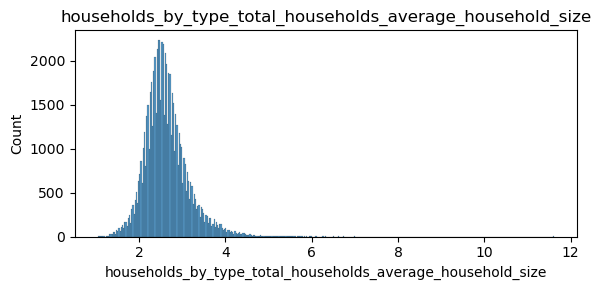

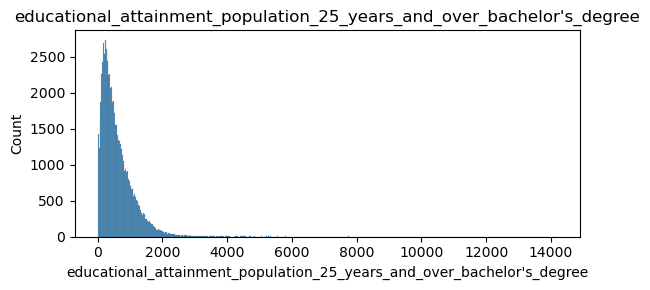

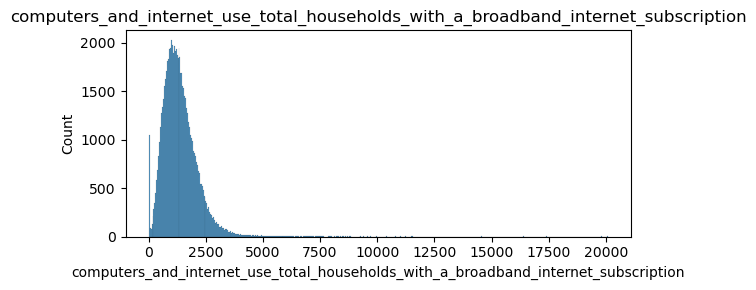

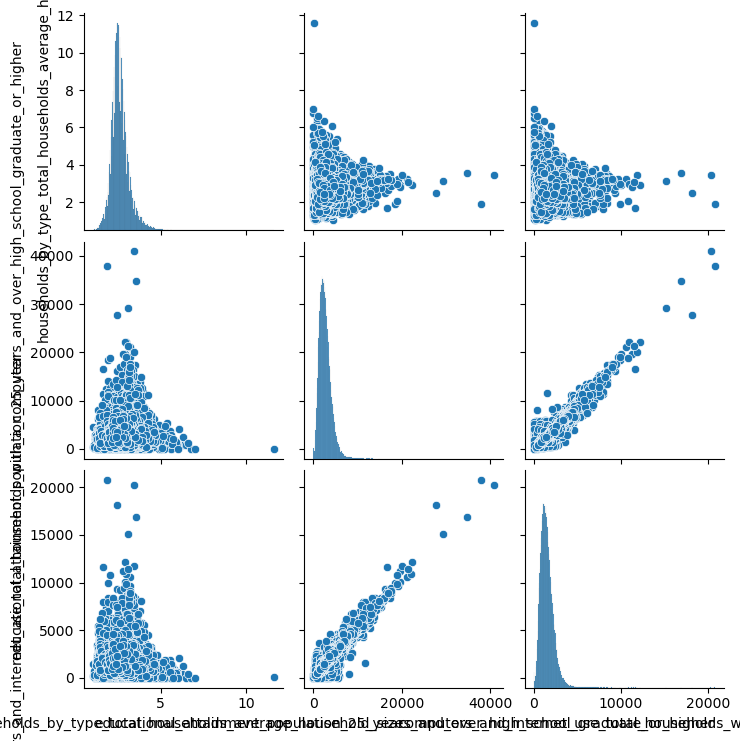

In [60]:
# histograms
sample_cols = [
    'households_by_type_total_households_average_household_size',
    "educational_attainment_population_25_years_and_over_bachelor's_degree",
    'computers_and_internet_use_total_households_with_a_broadband_internet_subscription'
]

for col in sample_cols:
    if col in df_acs_2019.columns:
        plt.figure(figsize=(6,3))
        sns.histplot(df_acs_2019[col], kde=False)
        plt.title(col)
        plt.tight_layout()
        plt.show()

# pairplot
subset_cols = [
    'households_by_type_total_households_average_household_size',
    'educational_attainment_population_25_years_and_over_high_school_graduate_or_higher',
    'computers_and_internet_use_total_households_with_a_computer'
]

existing = [c for c in subset_cols if c in df_acs_2019.columns]

if len(existing) >= 2:
    sns.pairplot(df_acs_2019[existing].dropna())

### Closing Summary of EDA  

The exploratory data analysis for the 2019 ACS subset shows that the cleaned variables behave as expected, with distributions, correlations, and summary statistics aligning with known demographic patterns. Household size, educational attainment, and broadband access all display realistic ranges and shapes, confirming that the preprocessing steps were effective. Overall, the EDA results look correct and provide a solid foundation for deeper analysis in later stages of the project.

---

## Save Processed Data
 
All cleaned and transformed data fields generated during preprocessing will be saved in the processed folder within the project repository. This ensures a clear separation between raw inputs and analysis‑ready outputs, supporting reproducibility and transparent version control. The processed datasets will be available at: https://github.com/tdjohnson3210-oss/access-barriers-analysis

In [64]:
df_merged.to_parquet("df_merged.parquet", index=False)
df_csp_processed.to_parquet("df_csp_processed.parquet", index=False)
print("Saved df_merged.parquet and df_csp_processed.parquet in current folder.")

Saved df_merged.parquet and df_csp_processed.parquet in current folder.
